In [ ]:
# Importar las bibliotecas necesarias
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
from tensorflow.keras.metrics import Recall, Precision
from tensorflow.keras.preprocessing import image
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import kagglehub
from google.colab import drive

drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/checkpoints', exist_ok=True)

Mounted at /content/drive


In [ ]:
#Dtset load
path = kagglehub.dataset_download("paultimothymooney/breast-histopathology-images")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'breast-histopathology-images' dataset.
Path to dataset files: /kaggle/input/breast-histopathology-images


In [ ]:
#dataset view
def explorar(ruta, max_items=5, profundidad=0, max_profundidad=3):
    if profundidad > max_profundidad:
        return
    items = sorted(os.listdir(ruta))
    print("  " * profundidad + f"[{os.path.basename(ruta) or ruta}] -> {len(items)} elementos")
    for item in items[:max_items]:
        item_path = os.path.join(ruta, item)
        if os.path.isdir(item_path):
            explorar(item_path, max_items=max_items, profundidad=profundidad + 1, max_profundidad=max_profundidad)
        else:
            print("  " * (profundidad + 1) + f"- {item}")

explorar(path)

[breast-histopathology-images] -> 280 elementos
  [10253] -> 2 elementos
    [0] -> 479 elementos
      - 10253_idx5_x1001_y1001_class0.png
      - 10253_idx5_x1001_y1051_class0.png
      - 10253_idx5_x1001_y1101_class0.png
      - 10253_idx5_x1001_y1151_class0.png
      - 10253_idx5_x1001_y1201_class0.png
    [1] -> 70 elementos
      - 10253_idx5_x501_y351_class1.png
      - 10253_idx5_x501_y401_class1.png
      - 10253_idx5_x551_y301_class1.png
      - 10253_idx5_x551_y351_class1.png
      - 10253_idx5_x551_y401_class1.png
  [10254] -> 2 elementos
    [0] -> 772 elementos
      - 10254_idx5_x1001_y1001_class0.png
      - 10254_idx5_x1001_y1051_class0.png
      - 10254_idx5_x1001_y1201_class0.png
      - 10254_idx5_x1001_y1251_class0.png
      - 10254_idx5_x1001_y1301_class0.png
    [1] -> 76 elementos
      - 10254_idx5_x1601_y1301_class1.png
      - 10254_idx5_x1601_y1351_class1.png
      - 10254_idx5_x1601_y1401_class1.png
      - 10254_idx5_x1601_y1451_class1.png
      - 10254_id

In [ ]:
# catalogar pacientes con etiquetas
records = []
for patient_id in os.listdir(path):
    patient_path = os.path.join(path, patient_id)
    if not os.path.isdir(patient_path):
        continue
    for label in ['0', '1']:
        label_path = os.path.join(patient_path, label)
        if not os.path.isdir(label_path):
            continue
        for fname in os.listdir(label_path):
            if fname.endswith('.png'):
                records.append({
                    'filepath': os.path.join(label_path, fname),
                    'label': label,          # como texto: lo pide flow_from_dataframe
                    'patient_id': patient_id
                })

df_full = pd.DataFrame(records)
print("Total de imágenes:", df_full.shape[0])
print("Pacientes:", df_full['patient_id'].nunique())
print(df_full['label'].value_counts())

Total de imágenes: 277524
Pacientes: 279
label
0    198738
1     78786
Name: count, dtype: int64


In [ ]:
N_PACIENTES = 120  #nro de pacientes

rng = np.random.default_rng(seed=42)
pacientes_todos = np.sort(df_full['patient_id'].unique())
pacientes_muestra = rng.choice(pacientes_todos, size=min(N_PACIENTES, len(pacientes_todos)), replace=False)

df = df_full[df_full['patient_id'].isin(pacientes_muestra)].reset_index(drop=True)
print("Imágenes en la muestra:", df.shape[0])
print(df['label'].value_counts())

Imágenes en la muestra: 123674
label
0    86163
1    37511
Name: count, dtype: int64


In [ ]:
# split train/val/test por paciente
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_val_idx, test_idx = next(gss1.split(df, groups=df['patient_id']))
df_train_val = df.iloc[train_val_idx]
df_test = df.iloc[test_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=42)  # ~0.15/0.85
train_idx, val_idx = next(gss2.split(df_train_val, groups=df_train_val['patient_id']))
df_train = df_train_val.iloc[train_idx].reset_index(drop=True)
df_val = df_train_val.iloc[val_idx].reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print("Train:", len(df_train), " Val:", len(df_val), " Test:", len(df_test))

# ningun paciente se repite entre conjuntos
assert not (set(df_train['patient_id']) & set(df_val['patient_id']))
assert not (set(df_train['patient_id']) & set(df_test['patient_id']))
assert not (set(df_val['patient_id']) & set(df_test['patient_id']))
print("Sin fuga de pacientes entre splits")

Train: 83850  Val: 20523  Test: 19301
Sin fuga de pacientes entre splits


In [ ]:
img_size = 128
batch_size = 64
epochs = 30
initial_learning_rate = 0.00001

train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.resnet50.preprocess_input,
    rotation_range=90, width_shift_range=0.2, height_shift_range=0.2,
    shear_range=0.2, zoom_range=0.2, horizontal_flip=True, vertical_flip=True,
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator(preprocessing_function=tf.keras.applications.resnet50.preprocess_input)
test_datagen = ImageDataGenerator(preprocessing_function=tf.keras.applications.resnet50.preprocess_input)

train_generator = train_datagen.flow_from_dataframe(
    df_train, x_col='filepath', y_col='label',
    target_size=(img_size, img_size), batch_size=batch_size, class_mode='binary'
)
val_generator = val_datagen.flow_from_dataframe(
    df_val, x_col='filepath', y_col='label',
    target_size=(img_size, img_size), batch_size=batch_size, class_mode='binary'
)
val_eval_generator = val_datagen.flow_from_dataframe(
    df_val, x_col='filepath', y_col='label',
    target_size=(img_size, img_size), batch_size=batch_size, class_mode='binary', shuffle=False
)
test_generator = test_datagen.flow_from_dataframe(
    df_test, x_col='filepath', y_col='label',
    target_size=(img_size, img_size), batch_size=batch_size, class_mode='binary', shuffle=False
)

Found 83850 validated image filenames belonging to 2 classes.
Found 20523 validated image filenames belonging to 2 classes.
Found 20523 validated image filenames belonging to 2 classes.
Found 19301 validated image filenames belonging to 2 classes.


In [ ]:
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(img_size, img_size, 3))

# Descongelar la ultima capa
for layer in base_model.layers:
    layer.trainable = layer.name.startswith('conv5')

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
!ls -la /content/drive/MyDrive/checkpoints/

total 432697
drwx------  2 root root      4096 Oct  3 16:17 .
drwx------ 28 root root      4096 Oct 15 22:14 ..
-rw-------  1 root root 221536497 Oct  4 19:52 mejor_modelo.keras
-rw-------  1 root root 221536498 Oct  4 20:48 modelo_final.keras


In [ ]:
"""model = load_model('/content/drive/MyDrive/checkpoints/mejor_modelo.keras')"""

In [ ]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
predictions = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=predictions)

In [ ]:
# Compilar el modelo
optimizer = Adam(learning_rate=initial_learning_rate)
model.compile(optimizer=optimizer, loss='binary_crossentropy',
              metrics=['accuracy', Recall(name='recall'), Precision(name='precision')])

reduce_lr = ReduceLROnPlateau(monitor='val_loss', mode='min', factor=0.2, patience=4, min_lr=1e-6, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', mode='min', patience=7, restore_best_weights=True, verbose=1)

In [ ]:
#checkpoint branch
reduce_lr = ReduceLROnPlateau(monitor='val_loss', mode='min', factor=0.2, patience=4, min_lr=1e-6, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', mode='min', patience=7, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint(
    '/content/drive/MyDrive/checkpoints/mejor_modelo.keras',
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)

train_labels = train_generator.classes
class_counts = np.bincount(train_labels)
n_total = len(train_labels)
n_classes = len(class_counts)
balanced_weights = {i: n_total / (n_classes * class_counts[i]) for i in range(n_classes)}
print(balanced_weights)

{0: np.float64(0.7171202298889896), 1: np.float64(1.6514357742151495)}


In [ ]:
history = model.fit(
    train_generator,
    epochs=epochs,
    validation_data=val_generator,
    callbacks=[reduce_lr, early_stop, checkpoint],
    class_weight=balanced_weights
)

Epoch 1/40
1311/1311 ━━━━━━━━━━━━━━━━━━━━ 0s 382ms/step - accuracy: 0.8594 - loss: 0.3210 - precision: 0.7177 - recall: 0.8781
Epoch 1: val_loss improved from None to 0.35371, saving model to /content/drive/MyDrive/checkpoints/mejor_modelo.keras

Epoch 1: finished saving model to /content/drive/MyDrive/checkpoints/mejor_modelo.keras
1311/1311 ━━━━━━━━━━━━━━━━━━━━ 566s 414ms/step - accuracy: 0.8597 - loss: 0.3220 - precision: 0.7198 - recall: 0.8786 - val_accuracy: 0.8583 - val_loss: 0.3537 - val_precision: 0.8127 - val_recall: 0.8266 - learning_rate: 1.0000e-05
Epoch 2/40
1311/1311 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - accuracy: 0.8576 - loss: 0.3229 - precision: 0.7138 - recall: 0.8772
Epoch 2: val_loss did not improve from 0.35371
1311/1311 ━━━━━━━━━━━━━━━━━━━━ 489s 373ms/step - accuracy: 0.8612 - loss: 0.3169 - precision: 0.7224 - recall: 0.8793 - val_accuracy: 0.8580 - val_loss: 0.3543 - val_precision: 0.8157 - val_recall: 0.8207 - learning_rate: 1.0000e-05
Epoch 3/40
1311/1311 ━━━━

In [ ]:
model.save('/content/drive/MyDrive/checkpoints/modelo_final.keras')
print("Modelo guardado en Drive.")

Modelo guardado en Drive.


321/321 ━━━━━━━━━━━━━━━━━━━━ 139s 434ms/step
Umbral óptimo (max F2): 0.194
  precision en ese punto: 0.686
  recall en ese punto:    0.931


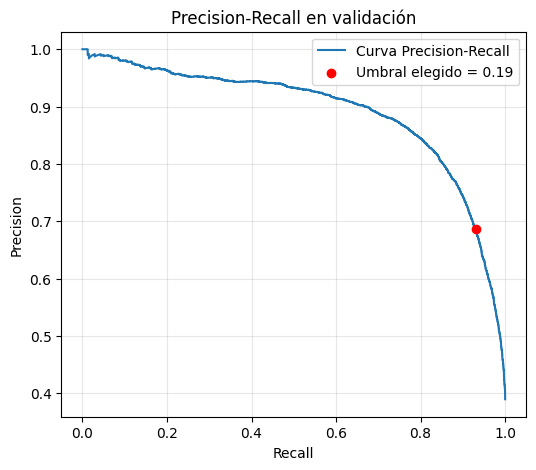

In [ ]:

val_probs = model.predict(val_eval_generator).ravel()
val_true = val_eval_generator.classes

precision, recall, thresholds = precision_recall_curve(val_true, val_probs)

# F2: pesa el recall el doble que la precision
beta = 2
f2_scores = (1 + beta**2) * (precision * recall) / (beta**2 * precision + recall + 1e-9)

# precision_recall_curve devuelve un threshold menos que precision/recall
# (el último punto corresponde a threshold=infinito), por eso el [:-1]
best_idx = f2_scores[:-1].argmax()
best_threshold = thresholds[best_idx]

print(f"Umbral óptimo (max F2): {best_threshold:.3f}")
print(f"  precision en ese punto: {precision[best_idx]:.3f}")
print(f"  recall en ese punto:    {recall[best_idx]:.3f}")

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label='Curva Precision-Recall')
plt.scatter(recall[best_idx], precision[best_idx], color='red', zorder=5,
            label=f'Umbral elegido = {best_threshold:.2f}')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall en validación')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
target_recall = 0.85
valid_idx = np.where(recall[:-1] >= target_recall)[0]
best_idx_recall_floor = valid_idx[np.argmax(precision[valid_idx])]
best_threshold_recall_floor = thresholds[best_idx_recall_floor]

print(f"Umbral (recall >= {target_recall}, precisión máxima): {best_threshold_recall_floor:.3f}")
print(f"  precision: {precision[best_idx_recall_floor]:.3f}")
print(f"  recall:    {recall[best_idx_recall_floor]:.3f}")

Umbral (recall >= 0.85, precisión máxima): 0.440
  precision: 0.803
  recall:    0.850


In [ ]:
from tensorflow.keras.models import load_model
model = load_model('/content/drive/MyDrive/checkpoints/modelo_final.keras')

In [ ]:
y_pred_recall_floor = (test_probs > best_threshold_recall_floor).astype(int)
print("=== Umbral (piso de recall) ===")
print(confusion_matrix(y_true_test, y_pred_recall_floor))
print(classification_report(y_true_test, y_pred_recall_floor, target_names=list(test_generator.class_indices.keys())))

=== Umbral (piso de recall) ===
[[13078  2093]
 [  604  3526]]
              precision    recall  f1-score   support

           0       0.96      0.86      0.91     15171
           1       0.63      0.85      0.72      4130

    accuracy                           0.86     19301
   macro avg       0.79      0.86      0.81     19301
weighted avg       0.89      0.86      0.87     19301



In [ ]:
img_path = "16165_idx5_x451_y801_class0.png"
img_size = 224
# Cargar la imagen y ajustarla al tamaño esperado
img = image.load_img(img_path, target_size=(img_size, img_size))

# Convertir la imagen a un array
img_array = image.img_to_array(img)

# Expandir dimensiones para representar un lote (batch)
img_array = np.expand_dims(img_array, axis=0)

# Normalizar la imagen (rescale 1.0/255 si es necesario)
img_array = img_array / 255.0

# Hacer la predicción
prediction = model.predict(img_array)

# Obtener probabilidades
carcinoma_prob = prediction[0][0]  # Probabilidad de Carcinoma (Clase 1)
normal_prob = 1 - carcinoma_prob   # Probabilidad de Normal (Clase 0)

# Interpretar el resultado y mostrar porcentajes
if carcinoma_prob > best_threshold_recall_floor:  # Umbral definido durante el entrenamiento
    print(f"La imagen se clasifica como: Carcinoma (Clase 1)")
else:
    print(f"La imagen se clasifica como: Normal (Clase 0)")

print(f"Probabilidad de Carcinoma: {carcinoma_prob * 100:.2f}%")
print(f"Probabilidad de Normal: {normal_prob * 100:.2f}%")